In [1]:
from tqdm import tqdm
import os
from os import listdir
from os.path import isfile, join, getsize
import gc
import sys
import time
from math import pi
from more_itertools import grouper
from functools import wraps
import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from IPython.display import HTML
import pickle

import torch
from torch import nn, einsum
from torch.nn.parallel.data_parallel import DataParallel
import torch.multiprocessing as mp
import torch.nn.functional as F
import torchaudio
from torchaudio.transforms import Resample
from torchvision.models.detection import fasterrcnn_mobilenet_v3_large_320_fpn
from torchvision.utils import draw_bounding_boxes
from pytorchvideo.data.encoded_video import EncodedVideo
from pytorchvideo.transforms import UniformTemporalSubsample
from speechbrain.pretrained import SepformerSeparation as separator
import torchshow as ts
from einops import rearrange, repeat

device = torch.device("cuda:0" if torch.cuda.is_available() else "cpu")
deviceEval = device
sns.set()

%load_ext autoreload
%autoreload 2

In [2]:
sys.path.append(join(os.path.dirname(os.path.abspath('..')), 'hand4whole'))
sys.path.append(join(join(os.path.dirname(os.path.abspath('..')), 'hand4whole'),'main'))
sys.path.append(join(join(os.path.dirname(os.path.abspath('..')), 'hand4whole'),'common'))

from config import cfg
from model import get_model
from utils.preprocessing import process_bbox, generate_patch_image
from utils.human_models import smpl_x
from utils.vis import render_mesh, save_obj

sys.path.append(join(os.path.abspath('..'), 'datasets'))
sys.path.append(join(os.path.abspath('..'), 'processing'))
sys.path.append(join(os.path.abspath('..'), 'core'))
sys.path.append(join(os.path.abspath('..'), 'rendering'))

from configuration import cf
from box_detection import interpolate_bbox, Resize_with_pad
from videoTransform import transform_video, transform_audio
from pickle_sequence import write_seq, read_seq
from renderer import render_silhouettes, batch_intrinsic_camera, video_masking, render_projection

from torchvision.transforms import Compose, Lambda, Resize, CenterCrop, Normalize
from pytorchvideo.transforms import ApplyTransformToKey, ShortSideScale, UniformTemporalSubsample

INFO:OpenGL.acceleratesupport:No OpenGL_accelerate module loaded: No module named 'OpenGL_accelerate'


In [3]:
# install pytorch3d
# import sys
# import torch
# pyt_version_str=torch.__version__.split("+")[0].replace(".", "")
# version_str="".join([
#     f"py3{sys.version_info.minor}_cu",
#     torch.version.cuda.replace(".",""),
#     f"_pyt{pyt_version_str}"
# ])
# !pip install --no-index --no-cache-dir pytorch3d -f https://dl.fbaipublicfiles.com/pytorch3d/packaging/wheels/{version_str}/download.html

## Load models

In [3]:
# rcnn load

model_bbox = fasterrcnn_mobilenet_v3_large_320_fpn(pretrained=True)
model_bbox=model_bbox.eval()
model_bbox=model_bbox.to(deviceEval)

# smpl-x snapshot load

model_path = '../../hand4whole/demo/snapshot_6.pth.tar'
assert os.path.exists(model_path), 'Cannot find model at ' + model_path
print('Load checkpoint from {}'.format(model_path))
model_smplx = get_model('test')
model_smplx = DataParallel(model_smplx)
ckpt = torch.load(model_path, map_location=torch.device("cpu"))
model_smplx.load_state_dict(ckpt['network'], strict=False)
model_smplx = model_smplx.eval().to(deviceEval)

# sepformer load

model_sepformer = separator.from_hparams(source="speechbrain/sepformer-wham-enhancement", savedir='pretrained_models/sepformer-wham-enhancement', run_opts={"device":"cpu"})
model_sepformer = model_sepformer.eval()

# Sampling

subsampler = Resample(cf.sample_rate, cf.sepformer_rate).to(deviceEval)
upsampler = Resample(cf.sepformer_rate, cf.sample_rate).to(deviceEval)

Load checkpoint from ../../hand4whole/demo/snapshot_6.pth.tar


INFO:speechbrain.pretrained.fetching:Fetch hyperparams.yaml: Using existing file/symlink in pretrained_models/sepformer-wham-enhancement/hyperparams.yaml.
INFO:speechbrain.pretrained.fetching:Fetch custom.py: Delegating to Huggingface hub, source speechbrain/sepformer-wham-enhancement.
INFO:speechbrain.pretrained.fetching:Fetch encoder.ckpt: Using existing file/symlink in pretrained_models/sepformer-wham-enhancement/encoder.ckpt.
INFO:speechbrain.pretrained.fetching:Fetch masknet.ckpt: Using existing file/symlink in pretrained_models/sepformer-wham-enhancement/masknet.ckpt.
INFO:speechbrain.pretrained.fetching:Fetch decoder.ckpt: Using existing file/symlink in pretrained_models/sepformer-wham-enhancement/decoder.ckpt.
INFO:speechbrain.utils.parameter_transfer:Loading pretrained files for: encoder, masknet, decoder


## Run

In [4]:
def body_from_video(video, extended=False, draw_bbox=False):

    # compute bbox

    video = rearrange(video ,  "c t h w -> t c h w")/255
    frames, _, h, w = video.shape
    with torch.no_grad():
        res=model_bbox(video.to(deviceEval))
    bbox=interpolate_bbox(res, h, w).int()

    # make patches

    vids=[]
    max_w = max( bbox[:, 2]-bbox[:, 0]+1 )
    max_h = max( bbox[:, 3]-bbox[:, 1]+1 )
    resize_pad = Resize_with_pad(max_w, max_h)
    for i in range(frames):
        xmin, ymin, xmax, ymax = bbox[i]
        vid=video[i][:, ymin:ymax, xmin:xmax ]
        dw, dh, vid = resize_pad(vid)
        bbox[i] = torch.tensor([xmin-dw, ymin-dh, xmax+dw, ymax+dh])
        vids.append(vid)
    vids=torch.stack(vids)
    if(draw_bbox):
        ts.show(draw_bounding_boxes((video*255)[0].byte(), bbox.int()))

    # compute targets

    inputs, targets, meta_info = {'img': vids.to(deviceEval)}, {}, {}
    with torch.no_grad():
        out = model_smplx(inputs, targets, meta_info, 'test')
    bbox = bbox.float()
    bbox[:, [0,2]] = bbox[:, [0,2]]/w
    bbox[:, [1,3]] = bbox[:, [1,3]]/h
    out['bbox']=bbox.to(deviceEval)

    del out['img']
    del out['joint_img']
    del out['smplx_mesh_cam']

    return out

In [5]:
def pickle_media_pose(path, duration = 1):

    stream = EncodedVideo.from_path(path)
    duration = stream.duration
    slice_duration = 1
    nb_frames = slice_duration * cf.fps
    seq_path = os.path.dirname(path) + '/seq/' + os.path.basename(path)[:-4] + '.bin'
    rendered_video=None
    if(not isfile(seq_path)):

        # Pickle sequence
        
        seq_file = open(seq_path, 'wb')
        for i in range(0, int(duration), slice_duration):

            t0 = time.time()

            seq = stream.get_clip(start_sec=i, end_sec = min(i+slice_duration, duration))

            print('get clip: ', time.time()-t0)
            t0 = time.time()

            # Extract body

            seq.update(body_from_video(UniformTemporalSubsample(nb_frames)(seq['video'])))

            print('body: ', time.time()-t0)
            t0 = time.time()

            seq['audio'] = transform_audio(nb_frames)(seq)['audio']
            seq['clean_audio'] = upsampler(model_sepformer(subsampler(seq["audio"].to(deviceEval)).unsqueeze(0)).squeeze(-1)).squeeze(0).to(deviceEval)

            # seq = { key : torch.tensor(value) for key, value in seq.items()}
            rendered_video = video_masking(seq["video"], seq, model_smplx)            

            print('clean audio: ', time.time()-t0)
            t0 = time.time()

            # Flush to free some memory
            for key in seq.keys():
                seq[key] = seq[key].tolist()
            write_seq(seq, seq_file)
            print('write mem: ', time.time()-t0)

        seq_file.close()
    return seq['audio']


In [6]:
ts.show_video(rearrange(rendered_video, 'c f h w -> f h w c'))

NameError: name 'rendered_video' is not defined

In [10]:
print(rendered_audio)

None


In [ ]:
rendered_video = pickle_media_pose('/home/jeanmanuel/memory-perceiver/memory_perceiver/data_test/Chain Hang Low BEST DANCE - Fik-Shun - Do Your Chain Hang Low copy 2.mp4')

In [7]:
root_path = '/home/jeanmanuel/memory-perceiver/memory_perceiver/data_test'
pathes = [join(root_path, f) for f in listdir(root_path) if isfile(join(root_path, f))]
rendered_video=None
for path in pathes:
    rendered_audio = pickle_media_pose(path)

get clip:  0.1848154067993164
body:  7.113295555114746
clean audio:  1.0645384788513184
write mem:  3.4967200756073
get clip:  1.895057201385498
body:  5.930907487869263
clean audio:  0.35006022453308105
write mem:  3.656649112701416
get clip:  1.0493416786193848
body:  5.986951589584351
clean audio:  0.4945833683013916
write mem:  3.4284896850585938
get clip:  1.2461740970611572
body:  6.982630968093872
clean audio:  0.3709890842437744
write mem:  3.7205231189727783
get clip:  1.2608449459075928
body:  6.999952077865601
clean audio:  1.1847927570343018
write mem:  3.434126138687134
get clip:  1.193223237991333
body:  6.2657694816589355
clean audio:  0.31472349166870117
write mem:  3.518554925918579
get clip:  1.1520860195159912
body:  6.384189128875732
clean audio:  0.534454345703125
write mem:  3.9272541999816895


In [32]:
path='/home/jeanmanuel/memory-perceiver/memory_perceiver/data_test/seq/Chain Hang Low BEST DANCE - Fik-Shun - Do Your Chain Hang Low copy 3.bin'
path_vid='/home/jeanmanuel/memory-perceiver/memory_perceiver/data_test/Chain Hang Low BEST DANCE - Fik-Shun - Do Your Chain Hang Low copy 3.mp4'
start=1
stop=6
seq=read_seq(path, start, stop) 
seq = {part: torch.tensor(item) for part, item in seq.items()}
stream = EncodedVideo.from_path(path_vid)
vid=stream.get_clip(start_sec=start, end_sec = stop)
audio = transform_audio(int((stop-start)*cf.fps))(vid)['audio']
clean_audio = upsampler(model_sepformer(subsampler(vid["audio"].to(deviceEval)).unsqueeze(0)).squeeze(-1)).squeeze(0).to(deviceEval)

In [33]:
len(clean_audio)

307200

In [35]:
torchaudio.save('./monitor/audio.wav', audio[None,:].detach().cpu(), cf.sample_rate)

In [24]:
a=torch.tensor([[1,2,3], [4,5,6]])

In [28]:
a[None, 0]

tensor([[1, 2, 3]])

In [21]:
audio[None,:]

tensor([[ 0.0472,  0.0472,  0.0194,  ...,  0.0963, -0.0394, -0.0221]])

In [20]:
torch.tensor(seq[list(cf.body_parts.keys())[0]]).shape

torch.Size([16, 3])

In [12]:
torch.tensor(seq['clean_audio']).shape

torch.Size([30720])

In [13]:
30720/1920

16.0

In [15]:
seq.keys()

dict_keys(['clean_audio', 'smplx_root_pose', 'smplx_body_pose', 'smplx_lhand_pose', 'smplx_rhand_pose', 'smplx_jaw_pose', 'smplx_expr', 'cam_trans', 'bbox', 'smplx_shape'])

In [30]:
vid['video'].shape

torch.Size([3, 12, 720, 1280])

In [33]:
seq['smplx_root_pose'].shape

AttributeError: 'list' object has no attribute 'shape'

(12, 720, 1280, 3)


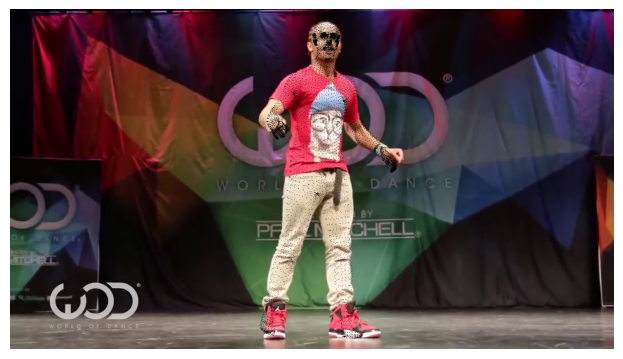

In [37]:
rendered_video = video_masking(vid['video'], seq, model_smplx)  
ts.show_video(rearrange(rendered_video, 'c f h w -> f h w c'))

In [14]:
vis_vid = rearrange(CenterCrop((256, 456))(ShortSideScale(size=256)(UniformTemporalSubsample(32)(seq['video']))).to(deviceEval), 'c t h w -> t c h w')
frames, _, h, w = vis_vid.shape
cam_params = batch_intrinsic_camera(seq['bbox'], w, h)
rendered_video = render_silhouettes(vis_vid, seq['smplx_mesh_cam'], repeat(smpl_x.face, 'd1 d2 -> f d1 d2', f = 1), cam_params, device, hd=False)
# rendered_video = render_projection(vis_vid, seq['smplx_mesh_cam'], cam_params)
ts.show(rendered_video[0])

KeyError: 'video'

In [ ]:
ani=ts.show_video(vis_vid)
HTML(ani.to_jshtml())